In [106]:
# Olist E-commerce Analysis

## Objetivo do projeto
#Analisar a relação entre o tempo de entrega dos pedidos e as avaliações dos clientes.

## Investigações
#1. Pedidos com elevado tempo de entrega.
#2. Relação entre o tempo de entrega e as avaliações dos clientes.

In [107]:
## 1. Importação das bibliotecas
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [193]:
## 2. Carregamento dos dados
customers = pd.read_csv(r"C:\Users\AP\Desktop\olist_customers_dataset.csv\datas\raw\olist_customers_dataset.csv")
orders = pd.read_csv(r"C:\Users\AP\Desktop\olist_customers_dataset.csv\datas\raw\olist_orders_dataset.csv")
order_items = pd.read_csv(r"C:\Users\AP\Desktop\olist_customers_dataset.csv\datas\raw\olist_order_items_dataset.csv")
reviews = pd.read_csv(r"C:\Users\AP\Desktop\olist_customers_dataset.csv\datas\raw\olist_order_reviews_dataset.csv")

In [109]:
## 3. Preparação e limpeza dos dados
orders.shape

(99441, 8)

In [110]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [111]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


In [112]:
orders.isna().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

In [113]:
orders["order_purchase_timestamp"]=pd.to_datetime(orders["order_purchase_timestamp"])

In [114]:
orders["order_delivered_customer_date"]=pd.to_datetime(orders["order_delivered_customer_date"])

In [115]:
orders["delivery_time"]=(orders["order_delivered_customer_date"]-orders["order_purchase_timestamp"])

In [116]:
delivered_orders=orders[(orders["order_status"]=="delivered") & (orders["order_delivered_customer_date"].notna())].copy()

In [117]:
delivered_orders["delivery_days"]=delivered_orders["order_delivered_customer_date"]-delivered_orders["order_purchase_timestamp"]

In [118]:
delivered_orders["order_delivered_carrier_date"]=pd.to_datetime(delivered_orders["order_delivered_carrier_date"])

In [119]:
delivered_orders["purchase_to_carrier"]=delivered_orders["order_delivered_carrier_date"]-delivered_orders["order_purchase_timestamp"]

In [ ]:
delivered_orders["carrier_to_customer"]=(delivered_orders["order_delivered_customer_date"]-delivered_orders["order_delivered_carrier_date"]).dt.total_seconds()/86400

In [121]:
delivered_orders["delivery_month"]=(delivered_orders["order_delivered_customer_date"].dt.to_period("M"))

In [122]:
total_por_mes=delivered_orders.groupby("delivery_month").size()

In [123]:
datas_inconsistentes=delivered_orders[delivered_orders["carrier_to_customer"]<0].groupby("delivery_month").size()

In [124]:
taxa_entregas_por_mes=datas_inconsistentes/total_por_mes*100

In [125]:
valid_carrier_delivery=delivered_orders[delivered_orders["carrier_to_customer"]>=0].copy()

In [126]:
outliers=valid_carrier_delivery[valid_carrier_delivery["carrier_to_customer"]>24]

In [127]:
outliers=outliers.merge(customers[["customer_id","customer_state"]],on="customer_id",how="left")

In [128]:
outliers_por_estado=(outliers.groupby("customer_state").size())

In [129]:
delivered_orders=delivered_orders.merge(customers[["customer_id","customer_state"]],on="customer_id",how="left")

In [130]:
total_por_estado=(delivered_orders.groupby("customer_state").size())

In [131]:
taxa_de_outliers=outliers_por_estado/total_por_estado*100

In [132]:
tabela_estado=pd.concat([total_por_estado,outliers_por_estado,taxa_de_outliers],axis=1)

In [133]:
tabela_estado.columns=["total_entregue","outliers","taxa"]

In [134]:
outliers_sellers=outliers.merge(order_items[["order_id","seller_id"]],on="order_id",how="left")

In [135]:
outliers_por_seller=(outliers_sellers.drop_duplicates(["order_id","seller_id"]).groupby("seller_id").size().sort_values(ascending=False))

In [136]:
delivered_orders_sellers=delivered_orders.merge(order_items[["order_id","seller_id"]],on="order_id",how="left")

In [137]:
total_pedidos_seller=(delivered_orders_sellers.drop_duplicates(["order_id","seller_id"]).groupby("seller_id").size())

In [138]:
taxa_de_outliers=outliers_por_seller/total_pedidos_seller*100

In [139]:
tabela_outliers=pd.concat([outliers_por_seller,total_pedidos_seller,taxa_de_outliers],axis=1)

In [140]:
tabela_outliers.columns=["outliers_por_seller","total_pedidos_seller","taxa_de_outliers"]

In [141]:
total_seller_mais_50=total_pedidos_seller[total_pedidos_seller>=50]

In [142]:
outliers_50=outliers_por_seller[outliers_por_seller.index.isin(total_seller_mais_50.index)]

In [143]:
outliers_50=outliers_por_seller.reindex(total_seller_mais_50.index,fill_value=0)

In [144]:
taxa_outliers50=outliers_50/total_seller_mais_50*100

In [145]:
tabela_taxa50=pd.concat([outliers_50,total_seller_mais_50,taxa_outliers50],axis=1)

In [146]:
tabela_taxa50.columns=(["outliers_50","total_seller_mais_50","taxa_outliers50"])

In [147]:
analise_sellers=pd.DataFrame({"total_seller_mais_50":total_seller_mais_50,"outliers50":outliers_50,"taxa_outliers50":taxa_outliers50})

In [148]:
reviews_por_pedido=reviews.groupby("order_id").size()

In [149]:
reviews_por_pedido=(reviews.groupby("order_id")["review_score"].mean())

In [150]:
delivered_reviews=delivered_orders.merge(reviews_por_pedido.rename("review_score_mean"),on="order_id",how="left")

In [151]:
analise_reviews=delivered_reviews[delivered_reviews["review_score_mean"].notna()].copy()

In [152]:
analise_reviews["delivery_days"]=analise_reviews["order_delivered_customer_date"]-analise_reviews["order_purchase_timestamp"]

In [153]:
analise_reviews["delivery_days"]=analise_reviews["delivery_days"].dt.days

<Axes: xlabel='delivery_days', ylabel='review_score_mean'>

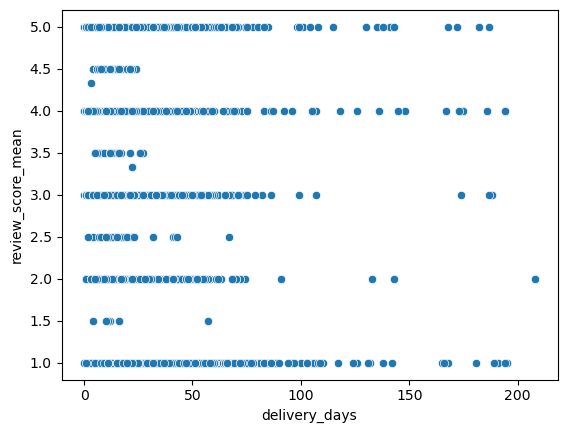

In [154]:
sns.scatterplot(data=analise_reviews,x="delivery_days",y="review_score_mean")

In [155]:
analise_reviews[["delivery_days","review_score_mean"]].corr()

,delivery_days,review_score_mean
delivery_days,1.000000,-0.334105
review_score_mean,-0.334105,1.000000


In [156]:
analise_sem_extremos=analise_reviews[analise_reviews["delivery_days"]<=28.5].copy()

In [157]:
analise_sem_extremos[["delivery_days","review_score_mean"]].corr()

,delivery_days,review_score_mean
delivery_days,1.000000,-0.172354
review_score_mean,-0.172354,1.000000


In [158]:
## 4. Análise exploratória
orders.isna().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
delivery_time                    2965
dtype: int64

In [159]:
orders[orders["order_approved_at"].isna()]["order_status"].value_counts()

order_status
canceled     141
delivered     14
created        5
Name: count, dtype: int64

In [160]:
orders[orders["order_delivered_carrier_date"].isna()]["order_status"].value_counts()

order_status
unavailable    609
canceled       550
invoiced       314
processing     301
created          5
approved         2
delivered        2
Name: count, dtype: int64

In [161]:
orders[orders["order_delivered_customer_date"].isna()]["order_status"].value_counts()

order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64

In [162]:
orders[(orders["order_status"]=="delivered") & (orders["order_approved_at"].isna())]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_time
5323,e04abd8149ef81b95221e88f6ed9ab6a,2127dc6603ac33544953ef05ec155771,delivered,2017-02-18 14:40:00,NaN,2017-02-23 12:04:47,2017-03-01 13:25:33,2017-03-17 00:00:00,10 days 22:45:33
16567,8a9adc69528e1001fc68dd0aaebbb54a,4c1ccc74e00993733742a3c786dc3c1f,delivered,2017-02-18 12:45:31,NaN,2017-02-23 09:01:52,2017-03-02 10:05:06,2017-03-21 00:00:00,11 days 21:19:35
19031,7013bcfc1c97fe719a7b5e05e61c12db,2941af76d38100e0f8740a374f1a5dc3,delivered,2017-02-18 13:29:47,NaN,2017-02-22 16:25:25,2017-03-01 08:07:38,2017-03-17 00:00:00,10 days 18:37:51
22663,5cf925b116421afa85ee25e99b4c34fb,29c35fc91fc13fb5073c8f30505d860d,delivered,2017-02-18 16:48:35,NaN,2017-02-22 11:23:10,2017-03-09 07:28:47,2017-03-31 00:00:00,18 days 14:40:12
23156,12a95a3c06dbaec84bcfb0e2da5d228a,1e101e0daffaddce8159d25a8e53f2b2,delivered,2017-02-17 13:05:55,NaN,2017-02-22 11:23:11,2017-03-02 11:09:19,2017-03-20 00:00:00,12 days 22:03:24
26800,c1d4211b3dae76144deccd6c74144a88,684cb238dc5b5d6366244e0e0776b450,delivered,2017-01-19 12:48:08,NaN,2017-01-25 14:56:50,2017-01-30 18:16:01,2017-03-01 00:00:00,11 days 05:27:53
38290,d69e5d356402adc8cf17e08b5033acfb,68d081753ad4fe22fc4d410a9eb1ca01,delivered,2017-02-19 01:28:47,NaN,2017-02-23 03:11:48,2017-03-02 03:41:58,2017-03-27 00:00:00,11 days 02:13:11
39334,d77031d6a3c8a52f019764e68f211c69,0bf35cac6cc7327065da879e2d90fae8,delivered,2017-02-18 11:04:19,NaN,2017-02-23 07:23:36,2017-03-02 16:15:23,2017-03-22 00:00:00,12 days 05:11:04
48401,7002a78c79c519ac54022d4f8a65e6e8,d5de688c321096d15508faae67a27051,delivered,2017-01-19 22:26:59,NaN,2017-01-27 11:08:05,2017-02-06 14:22:19,2017-03-16 00:00:00,17 days 15:55:20
61743,2eecb0d85f281280f79fa00f9cec1a95,a3d3c38e58b9d2dfb9207cab690b6310,delivered,2017-02-17 17:21:55,NaN,2017-02-22 11:42:51,2017-03-03 12:16:03,2017-03-20 00:00:00,13 days 18:54:08


In [163]:
orders[(orders["order_status"]=="delivered") & (orders["order_delivered_carrier_date"].isna())]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_time
73222,2aa91108853cecb43c84a5dc5b277475,afeb16c7f46396c0ed54acb45ccaaa40,delivered,2017-09-29 08:52:58,2017-09-29 09:07:16,NaN,2017-11-20 19:44:47,2017-11-14 00:00:00,52 days 10:51:49
92643,2d858f451373b04fb5c984a1cc2defaf,e08caf668d499a6d643dafd7c5cc498a,delivered,2017-05-25 23:22:43,2017-05-25 23:30:16,NaN,NaT,2017-06-23 00:00:00,NaT


In [164]:
orders[(orders["order_status"]=="delivered") & (orders["order_delivered_customer_date"].isna())]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_time
3002,2d1e2d5bf4dc7227b3bfebb81328c15f,ec05a6d8558c6455f0cbbd8a420ad34f,delivered,2017-11-28 17:44:07,2017-11-28 17:56:40,2017-11-30 18:12:23,NaT,2017-12-18 00:00:00,NaT
20618,f5dd62b788049ad9fc0526e3ad11a097,5e89028e024b381dc84a13a3570decb4,delivered,2018-06-20 06:58:43,2018-06-20 07:19:05,2018-06-25 08:05:00,NaT,2018-07-16 00:00:00,NaT
43834,2ebdfc4f15f23b91474edf87475f108e,29f0540231702fda0cfdee0a310f11aa,delivered,2018-07-01 17:05:11,2018-07-01 17:15:12,2018-07-03 13:57:00,NaT,2018-07-30 00:00:00,NaT
79263,e69f75a717d64fc5ecdfae42b2e8e086,cfda40ca8dd0a5d486a9635b611b398a,delivered,2018-07-01 22:05:55,2018-07-01 22:15:14,2018-07-03 13:57:00,NaT,2018-07-30 00:00:00,NaT
82868,0d3268bad9b086af767785e3f0fc0133,4f1d63d35fb7c8999853b2699f5c7649,delivered,2018-07-01 21:14:02,2018-07-01 21:29:54,2018-07-03 09:28:00,NaT,2018-07-24 00:00:00,NaT
92643,2d858f451373b04fb5c984a1cc2defaf,e08caf668d499a6d643dafd7c5cc498a,delivered,2017-05-25 23:22:43,2017-05-25 23:30:16,NaN,NaT,2017-06-23 00:00:00,NaT
97647,ab7c89dc1bf4a1ead9d6ec1ec8968a84,dd1b84a7286eb4524d52af4256c0ba24,delivered,2018-06-08 12:09:39,2018-06-08 12:36:39,2018-06-12 14:10:00,NaT,2018-06-26 00:00:00,NaT
98038,20edc82cf5400ce95e1afacc25798b31,28c37425f1127d887d7337f284080a0f,delivered,2018-06-27 16:09:12,2018-06-27 16:29:30,2018-07-03 19:26:00,NaT,2018-07-19 00:00:00,NaT


In [165]:
orders[(orders["order_status"]=="delivered") & (orders["order_approved_at"].isna())][["order_id","order_purchase_timestamp","order_approved_at","order_delivered_carrier_date","order_delivered_customer_date","order_estimated_delivery_date"]]

,order_id,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
5323,e04abd8149ef81b95221e88f6ed9ab6a,2017-02-18 14:40:00,NaN,2017-02-23 12:04:47,2017-03-01 13:25:33,2017-03-17 00:00:00
16567,8a9adc69528e1001fc68dd0aaebbb54a,2017-02-18 12:45:31,NaN,2017-02-23 09:01:52,2017-03-02 10:05:06,2017-03-21 00:00:00
19031,7013bcfc1c97fe719a7b5e05e61c12db,2017-02-18 13:29:47,NaN,2017-02-22 16:25:25,2017-03-01 08:07:38,2017-03-17 00:00:00
22663,5cf925b116421afa85ee25e99b4c34fb,2017-02-18 16:48:35,NaN,2017-02-22 11:23:10,2017-03-09 07:28:47,2017-03-31 00:00:00
23156,12a95a3c06dbaec84bcfb0e2da5d228a,2017-02-17 13:05:55,NaN,2017-02-22 11:23:11,2017-03-02 11:09:19,2017-03-20 00:00:00
26800,c1d4211b3dae76144deccd6c74144a88,2017-01-19 12:48:08,NaN,2017-01-25 14:56:50,2017-01-30 18:16:01,2017-03-01 00:00:00
38290,d69e5d356402adc8cf17e08b5033acfb,2017-02-19 01:28:47,NaN,2017-02-23 03:11:48,2017-03-02 03:41:58,2017-03-27 00:00:00
39334,d77031d6a3c8a52f019764e68f211c69,2017-02-18 11:04:19,NaN,2017-02-23 07:23:36,2017-03-02 16:15:23,2017-03-22 00:00:00
48401,7002a78c79c519ac54022d4f8a65e6e8,2017-01-19 22:26:59,NaN,2017-01-27 11:08:05,2017-02-06 14:22:19,2017-03-16 00:00:00
61743,2eecb0d85f281280f79fa00f9cec1a95,2017-02-17 17:21:55,NaN,2017-02-22 11:42:51,2017-03-03 12:16:03,2017-03-20 00:00:00


In [166]:
delivered_orders[delivered_orders["carrier_to_customer"]<0][["order_id","order_purchase_timestamp","order_delivered_carrier_date","order_delivered_customer_date","order_estimated_delivery_date","carrier_to_customer"]].sort_values("carrier_to_customer")

,order_id,order_purchase_timestamp,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,carrier_to_customer
33898,c1e2bf2b7dd3309f2f5356c6b63968fa,2017-02-10 10:19:10,2017-03-02 17:34:26,2017-02-14 15:15:57,2017-03-15 00:00:00,-16.096169
26660,fa3e37584f4fdb1ded0e0de700dfcb4e,2017-07-30 19:32:23,2017-08-09 18:18:43,2017-08-01 21:13:01,2017-08-18 00:00:00,-7.878958
43951,29941903985f944b0ffc49c479c1547d,2017-05-29 16:16:50,2017-06-09 15:07:29,2017-06-02 11:09:16,2017-06-23 00:00:00,-7.165428
14060,dceb62e8fa94b46006c9554fed743df0,2017-07-20 20:58:05,2017-08-01 18:23:30,2017-07-26 18:09:10,2017-08-11 00:00:00,-6.009954
48449,76458889992169d3135b264dc13aec67,2016-10-07 10:05:16,2016-10-26 11:43:06,2016-10-20 18:03:17,2016-11-29 00:00:00,-5.735984
69101,19feb5627c41ea1b36a8e50a469b3644,2016-10-07 17:09:56,2016-10-26 11:42:05,2016-10-20 19:07:54,2016-12-01 00:00:00,-5.690405
72738,d5558a097766363b8e76b38c43332e8a,2017-02-04 19:01:33,2017-02-15 08:55:26,2017-02-10 07:58:32,2017-03-01 00:00:00,-5.039514
40396,b866af202be0692766081310cd4085e1,2017-01-27 14:59:17,2017-02-20 02:32:08,2017-02-15 03:53:46,2017-04-17 00:00:00,-4.943310
6252,a1abeb653a4d4cd1e142ccb8c82cd069,2017-07-20 11:20:52,2017-07-28 16:57:58,2017-07-25 19:32:56,2017-08-14 00:00:00,-2.892384
76216,ea1dcb4757a844d2642547797bd5feb0,2017-07-18 13:38:29,2017-07-27 19:21:31,2017-07-25 19:43:10,2017-08-15 00:00:00,-1.984965


In [167]:
delivered_orders[delivered_orders["carrier_to_customer"]<0]["order_delivered_customer_date"].dt.to_period("M").sort_values(ascending=False)

87670    2017-08
26660    2017-08
24646    2017-08
56693    2017-08
6252     2017-07
9287     2017-07
13108    2017-07
66275    2017-07
76216    2017-07
18722    2017-07
14060    2017-07
24896    2017-07
48877    2017-07
43951    2017-06
21864    2017-06
73855    2017-03
72738    2017-02
33898    2017-02
40396    2017-02
20722    2016-10
48449    2016-10
69101    2016-10
92772    2016-10
Name: order_delivered_customer_date, dtype: period[M]

In [168]:
reviews["review_score"].value_counts()

review_score
5    57328
4    19142
1    11424
3     8179
2     3151
Name: count, dtype: int64

In [169]:
delivered_reviews["review_score_mean"].isna().sum()

np.int64(646)

<Axes: xlabel='delivery_days', ylabel='review_score_mean'>

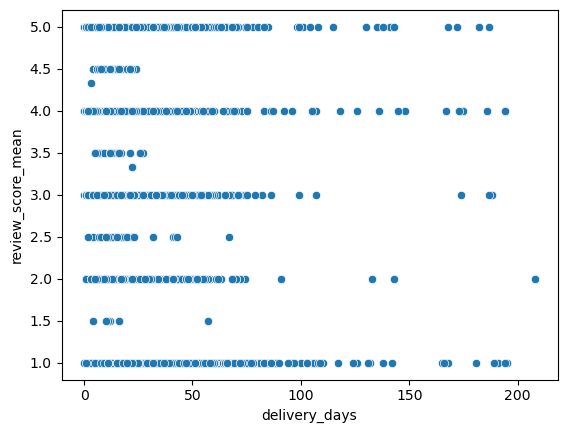

In [170]:
sns.scatterplot(data=analise_reviews,x="delivery_days",y="review_score_mean")

In [171]:
## 5. Investigação 1 — Pedidos com elevado tempo de entrega
outliers

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_time,delivery_days,purchase_to_carrier,carrier_to_customer,delivery_month,customer_state
0,ecab90c9933c58908d3d6add7c6f5ae3,761df82feda9778854c6dafdaeb567e4,delivered,2018-02-25 13:50:30,2018-02-25 14:47:35,2018-02-26 22:28:50,2018-03-27 23:29:14,2018-04-13 00:00:00,30 days 09:38:44,30 days 09:38:44,1 days 08:38:20,29.041944,2018-03,RR
1,8563039e855156e48fccee4d611a3196,5f16605299d698660e0606f7eae2d2f9,delivered,2018-02-17 15:59:46,2018-02-17 16:15:34,2018-02-20 23:03:56,2018-03-20 00:59:25,2018-03-20 00:00:00,30 days 08:59:39,30 days 08:59:39,3 days 07:04:10,27.080197,2018-03,TO
2,6a0a8bfbbe700284feb0845d95e0867f,68451b39b1314302c08c65a29f1140fc,delivered,2017-11-22 11:32:22,2017-11-22 11:46:50,2017-11-27 13:39:35,2017-12-28 19:43:00,2017-12-11 00:00:00,36 days 08:10:38,36 days 08:10:38,5 days 02:07:13,31.252373,2017-12,RJ
3,9d531c565e28c3e0d756192f84d8731f,d4faa220408c20e53595d2950f361f3b,delivered,2017-11-28 21:00:44,2017-12-01 09:31:15,2017-12-14 20:37:43,2018-01-23 21:38:52,2017-12-22 00:00:00,56 days 00:38:08,56 days 00:38:08,15 days 23:36:59,40.042465,2018-01,RJ
4,8fc207e94fa91a7649c5a5dab690272a,c69f8b33e62ecb30ff78ae46d7fb9241,delivered,2017-11-26 17:49:46,2017-11-26 17:58:34,2017-11-28 23:17:09,2018-01-20 13:42:22,2017-12-19 00:00:00,54 days 19:52:36,54 days 19:52:36,2 days 05:27:23,52.600845,2018-01,RJ
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4991,76a948cd55bf22799753720d4545dd2d,3f20a07b28aa252d0502fe7f7eb030a9,delivered,2018-01-30 02:41:30,2018-02-04 23:31:46,2018-01-31 18:11:58,2018-03-18 20:08:50,2018-03-02 00:00:00,47 days 17:27:20,47 days 17:27:20,1 days 15:30:28,46.081157,2018-03,AL
4992,4cf09d9e5ebbe0f91ddd7bf9aae891cd,07b6b4fe5fefb948fc76b6d2bdba77d8,delivered,2018-07-19 08:37:26,2018-07-21 03:25:17,2018-07-23 15:31:00,2018-08-21 01:12:45,2018-08-10 00:00:00,32 days 16:35:19,32 days 16:35:19,4 days 06:53:34,28.403993,2018-08,BA
4993,bdc11cf6acd11917b9ea3d91b95e1395,675292c8870ca23721c9c66a588dd982,delivered,2018-03-28 23:09:36,2018-03-28 23:26:49,2018-03-29 19:59:58,2018-04-26 12:54:39,2018-04-25 00:00:00,28 days 13:45:03,28 days 13:45:03,0 days 20:50:22,27.704641,2018-04,RJ
4994,38e9133ce29f6bbe35aed9c3863dce01,ad312389a098ceff46ce92c4595c06d0,delivered,2017-10-12 20:54:11,2017-10-14 03:28:24,2017-10-17 17:04:42,2017-11-21 17:06:59,2017-10-31 00:00:00,39 days 20:12:48,39 days 20:12:48,4 days 20:10:31,35.001586,2017-11,SP


In [172]:
outliers_por_estado

customer_state
AC      12
AL     128
AM      63
AP      22
BA     474
CE     235
DF      59
ES     139
GO     101
MA     132
MG     260
MS      48
MT      85
PA     253
PB      96
PE     202
PI      66
PR     121
RJ    1257
RN      61
RO      32
RR      19
RS     387
SC     235
SE      61
SP     423
TO      25
dtype: int64

In [174]:
tabela_estado

,total_entregue,outliers,taxa
customer_state,,,
AC,80,12,15.000000
AL,397,128,32.241814
AM,145,63,43.448276
AP,67,22,32.835821
BA,3256,474,14.557740
CE,1279,235,18.373729
DF,2080,59,2.836538
ES,1995,139,6.967419
GO,1957,101,5.160961


In [175]:
outliers_por_seller

seller_id
4869f7a5dfa277a7dca6462dcf3b52b2    138
4a3ca9315b744ce9f8e9374361493884    129
1f50f920176fa81dab994f9023523100    103
cc419e0650a3c5ba77189a1882b7556a     83
7c67e1448b00f6e969d365cea6b010ab     78
                                   ... 
04e38a233f726ef161074ab1c9b0399a      1
04fdea0c111866e6cf812f1570d6b5bd      1
fc906263ca5083d09dce42fe02247800      1
fbc14c0cf93505ef89f64665ffa4a7b5      1
042573af89b6d931f672efaf789d8358      1
Length: 1030, dtype: int64

In [176]:
total_pedidos_seller

seller_id
0015a82c2db000af6aaaf3ae2ecb0532      3
001cca7ae9ae17fb1caed9dfb1094831    195
002100f778ceb8431b7a1020ff7ab48f     50
003554e2dce176b5555353e4f3555ac8      1
004c9cd9d87a3c30c522c48c4fc07416    156
                                   ... 
ffc470761de7d0232558ba5e786e57b7     27
ffdd9f82b9a447f6f8d4b91554cc7dd3     18
ffeee66ac5d5a62fe688b9d26f83f534     14
fffd5413c0700ac820c7069d66d98c89     57
ffff564a4f9085cd26170f4732393726      8
Length: 2970, dtype: int64

In [177]:
tabela_outliers

,outliers_por_seller,total_pedidos_seller,taxa_de_outliers
seller_id,,,
4869f7a5dfa277a7dca6462dcf3b52b2,138.0,1124,12.277580
4a3ca9315b744ce9f8e9374361493884,129.0,1772,7.279910
1f50f920176fa81dab994f9023523100,103.0,1399,7.362402
cc419e0650a3c5ba77189a1882b7556a,83.0,1651,5.027256
7c67e1448b00f6e969d365cea6b010ab,78.0,973,8.016444
...,...,...,...
ff82e8873fba613f2261a9acc896fd84,NaN,4,NaN
ffa6adafb71b807dc13159e26431354c,NaN,17,NaN
ffad1e7127fb622cb64a900751590acd,NaN,10,NaN


In [178]:
total_seller_mais_50

seller_id
001cca7ae9ae17fb1caed9dfb1094831    195
002100f778ceb8431b7a1020ff7ab48f     50
004c9cd9d87a3c30c522c48c4fc07416    156
00ee68308b45bc5e2660cd833c3f81cc    135
00fc707aaaad2d31347cf883cd2dfe10    103
                                   ... 
fd386aa7bed2af3c7035c65506c9b4a3     69
fe2032dab1a61af8794248c8196565c9    293
febab0275244b9a49a623f0bd613ca2f    106
ff063b022a9a0aab91bad2c9088760b7     94
fffd5413c0700ac820c7069d66d98c89     57
Length: 425, dtype: int64

In [179]:
outliers_50

seller_id
001cca7ae9ae17fb1caed9dfb1094831     9
002100f778ceb8431b7a1020ff7ab48f     4
004c9cd9d87a3c30c522c48c4fc07416    16
00ee68308b45bc5e2660cd833c3f81cc     7
00fc707aaaad2d31347cf883cd2dfe10     6
                                    ..
fd386aa7bed2af3c7035c65506c9b4a3     3
fe2032dab1a61af8794248c8196565c9    20
febab0275244b9a49a623f0bd613ca2f     3
ff063b022a9a0aab91bad2c9088760b7     2
fffd5413c0700ac820c7069d66d98c89     7
Length: 425, dtype: int64

In [180]:
tabela_taxa50

,outliers_50,total_seller_mais_50,taxa_outliers50
seller_id,,,
001cca7ae9ae17fb1caed9dfb1094831,9,195,4.615385
002100f778ceb8431b7a1020ff7ab48f,4,50,8.000000
004c9cd9d87a3c30c522c48c4fc07416,16,156,10.256410
00ee68308b45bc5e2660cd833c3f81cc,7,135,5.185185
00fc707aaaad2d31347cf883cd2dfe10,6,103,5.825243
...,...,...,...
fd386aa7bed2af3c7035c65506c9b4a3,3,69,4.347826
fe2032dab1a61af8794248c8196565c9,20,293,6.825939
febab0275244b9a49a623f0bd613ca2f,3,106,2.830189


In [181]:
analise_sellers

,total_seller_mais_50,outliers50,taxa_outliers50
seller_id,,,
001cca7ae9ae17fb1caed9dfb1094831,195,9,4.615385
002100f778ceb8431b7a1020ff7ab48f,50,4,8.000000
004c9cd9d87a3c30c522c48c4fc07416,156,16,10.256410
00ee68308b45bc5e2660cd833c3f81cc,135,7,5.185185
00fc707aaaad2d31347cf883cd2dfe10,103,6,5.825243
...,...,...,...
fd386aa7bed2af3c7035c65506c9b4a3,69,3,4.347826
fe2032dab1a61af8794248c8196565c9,293,20,6.825939
febab0275244b9a49a623f0bd613ca2f,106,3,2.830189


In [186]:
## 6. Investigação 2 — Tempo de entrega e avaliação dos clientes

In [189]:
reviews_por_pedido

order_id
00010242fe8c5a6d1ba2dd792cb16214    5.0
00018f77f2f0320c557190d7a144bdd3    4.0
000229ec398224ef6ca0657da4fc703e    5.0
00024acbcdf0a6daa1e931b038114c75    4.0
00042b26cf59d7ce69dfabb4e55b4fd9    5.0
                                   ... 
fffc94f6ce00a00581880bf54a75a037    5.0
fffcd46ef2263f404302a634eb57f7eb    5.0
fffce4705a9662cd70adb13d4a31832d    5.0
fffe18544ffabc95dfada21779c9644f    5.0
fffe41c64501cc87c801fd61db3f6244    5.0
Name: review_score, Length: 98673, dtype: float64

In [183]:
delivered_reviews

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_time,delivery_days,purchase_to_carrier,carrier_to_customer,delivery_month,customer_state,review_score_mean
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,8 days 10:28:40,8 days 10:28:40,2 days 08:58:27,6.062650,2017-10,SP,4.0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,13 days 18:46:08,13 days 18:46:08,1 days 17:49:23,12.039410,2018-08,BA,4.0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,9 days 09:27:40,9 days 09:27:40,0 days 05:11:11,9.178113,2018-08,GO,5.0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00,13 days 05:00:36,13 days 05:00:36,3 days 18:11:53,9.450498,2017-12,RN,5.0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00,2 days 20:58:23,2 days 20:58:23,0 days 22:27:55,1.937824,2018-02,SP,5.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
96465,9c5dedf39a927c1b2549525ed64a053c,39bd1228ee8140590ac3aca26f2dfe00,delivered,2017-03-09 09:54:05,2017-03-09 09:54:05,2017-03-10 11:18:03,2017-03-17 15:08:01,2017-03-28 00:00:00,8 days 05:13:56,8 days 05:13:56,1 days 01:23:58,7.159699,2017-03,SP,5.0
96466,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,delivered,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02 00:00:00,22 days 04:38:58,22 days 04:38:58,1 days 10:23:44,20.760579,2018-02,SP,4.0
96467,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,delivered,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27 00:00:00,24 days 20:37:34,24 days 20:37:34,1 days 06:05:43,23.605451,2017-09,BA,5.0
96468,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15 00:00:00,17 days 02:04:27,17 days 02:04:27,3 days 18:06:36,13.331840,2018-01,RJ,2.0


In [185]:
analise_reviews

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_time,delivery_days,purchase_to_carrier,carrier_to_customer,delivery_month,customer_state,review_score_mean
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,8 days 10:28:40,8,2 days 08:58:27,6.062650,2017-10,SP,4.0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,13 days 18:46:08,13,1 days 17:49:23,12.039410,2018-08,BA,4.0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,9 days 09:27:40,9,0 days 05:11:11,9.178113,2018-08,GO,5.0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00,13 days 05:00:36,13,3 days 18:11:53,9.450498,2017-12,RN,5.0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00,2 days 20:58:23,2,0 days 22:27:55,1.937824,2018-02,SP,5.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
96465,9c5dedf39a927c1b2549525ed64a053c,39bd1228ee8140590ac3aca26f2dfe00,delivered,2017-03-09 09:54:05,2017-03-09 09:54:05,2017-03-10 11:18:03,2017-03-17 15:08:01,2017-03-28 00:00:00,8 days 05:13:56,8,1 days 01:23:58,7.159699,2017-03,SP,5.0
96466,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,delivered,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02 00:00:00,22 days 04:38:58,22,1 days 10:23:44,20.760579,2018-02,SP,4.0
96467,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,delivered,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27 00:00:00,24 days 20:37:34,24,1 days 06:05:43,23.605451,2017-09,BA,5.0
96468,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15 00:00:00,17 days 02:04:27,17,3 days 18:06:36,13.331840,2018-01,RJ,2.0


In [191]:
analise_reviews["delivery_days"]

0         8
1        13
2         9
3        13
4         2
         ..
96465     8
96466    22
96467    24
96468    17
96469     7
Name: delivery_days, Length: 95824, dtype: int64

In [192]:
## 7. Principais conclusões
"""A análise dos dados da Olist permitiu explorar o comportamento dos pedidos, o tempo de entrega e a avaliação atribuída pelos clientes.

De forma geral, as avaliações apresentaram resultados positivos, com uma média de aproximadamente **4,09 pontos** e uma mediana de **5 pontos**. Relativamente ao tempo de entrega, foi observada uma média de aproximadamente **12 dias**, existindo também alguns casos extremos com tempos de entrega bastante elevados.

A análise da relação entre o tempo de entrega e a avaliação dos clientes apresentou uma correlação de **-0,334**, indicando uma relação negativa entre as duas variáveis. Assim, os resultados sugerem que entregas mais demoradas tendem a estar associadas a avaliações inferiores, embora o tempo de entrega não seja o único fator responsável pela avaliação dos clientes.

Este projeto permitiu aplicar técnicas de preparação, exploração e análise de dados, utilizando informações provenientes de diferentes conjuntos de dados da Olist. A análise contribuiu para uma melhor compreensão do processo de entrega e da experiência dos clientes através das avaliações dos pedidos.
"""


'A análise dos dados da Olist permitiu explorar o comportamento dos pedidos, o tempo de entrega e a avaliação atribuída pelos clientes.\n\nDe forma geral, as avaliações apresentaram resultados positivos, com uma média de aproximadamente **4,09 pontos** e uma mediana de **5 pontos**. Relativamente ao tempo de entrega, foi observada uma média de aproximadamente **12 dias**, existindo também alguns casos extremos com tempos de entrega bastante elevados.\n\nA análise da relação entre o tempo de entrega e a avaliação dos clientes apresentou uma correlação de **-0,334**, indicando uma relação negativa entre as duas variáveis. Assim, os resultados sugerem que entregas mais demoradas tendem a estar associadas a avaliações inferiores, embora o tempo de entrega não seja o único fator responsável pela avaliação dos clientes.\n\nEste projeto permitiu aplicar técnicas de preparação, exploração e análise de dados, utilizando informações provenientes de diferentes conjuntos de dados da Olist. A análi